# Atividade Classificação e Pipelines com Scikit-learn

**Dupla:** Nathan Mateus de Lima e Vítor Oliveira Amorim  
**Professora:** Carolina Ribeiro Xavier  
**Disciplina:** Tecnologias para Data Science  

In [6]:
import pandas as pd 
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## Carregamento e Particionamento dos Dados

In [2]:
wine_data = load_wine(as_frame=True)
X, y = wine_data['data'], wine_data['target']
print(X.head())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

## Construção de Pipelines

### Pipeline A (Regressão Logística)

In [3]:
pipeline_A = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

pipeline_A.fit(X_train, y_train)

predictions_A = pipeline_A.predict(X_test)
print(confusion_matrix(y_test, predictions_A))

[[15  0  0]
 [ 0 18  0]
 [ 0  0 12]]


### Pipeline B (K-Vizinhos Mais Próximos)

In [4]:
pipeline_B = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

pipeline_B.fit(X_train, y_train)

predictions_B = pipeline_B.predict(X_test)
print(confusion_matrix(y_test, predictions_B))

[[15  0  0]
 [ 0 16  2]
 [ 0  1 11]]


## Validação Cruzada no Conjunto de Treino

In [5]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_A = cross_val_score(pipeline_A, X_train, y_train, cv=cv_strategy, scoring="accuracy")
scores_B = cross_val_score(pipeline_B, X_train, y_train, cv=cv_strategy, scoring='accuracy')

print("--- Pipeline A (Regressão Logística) ---")
print(f"Acurácias por fold: {scores_A}")
print(f"Acurácia média: {scores_A.mean():.4f} (+/- {scores_A.std():.4f})\n")

print("--- Pipeline B (K-NN) ---")
print(f"Acurácias por fold: {scores_B}")
print(f"Acurácia média: {scores_B.mean():.4f} (+/- {scores_B.std():.4f})")

--- Pipeline A (Regressão Logística) ---
Acurácias por fold: [0.96296296 0.96296296 1.         0.96153846 1.        ]
Acurácia média: 0.9775 (+/- 0.0184)

--- Pipeline B (K-NN) ---
Acurácias por fold: [0.88888889 1.         0.92592593 0.96153846 1.        ]
Acurácia média: 0.9553 (+/- 0.0431)


## Avaliação Final no Conjunto de Teste

Relatório de Classificação - Pipeline A (Regressão Logística)
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


Relatório de Classificação - Pipeline B (K-NN)
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.94      0.89      0.91        18
     class_2       0.85      0.92      0.88        12

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.94      0.93      0.93        45



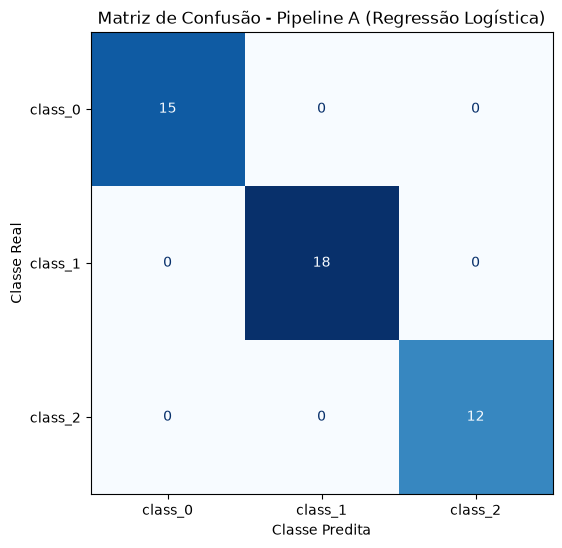

In [7]:
print("Relatório de Classificação - Pipeline A (Regressão Logística)")
print(classification_report(y_test, predictions_A, target_names=wine_data['target_names']))

print("\nRelatório de Classificação - Pipeline B (K-NN)")
print(classification_report(y_test, predictions_B, target_names=wine_data['target_names']))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_estimator(
    pipeline_A, X_test, y_test, 
    display_labels=wine_data['target_names'], 
    ax=ax, 
    cmap='Blues', 
    colorbar=False
)
plt.title("Matriz de Confusão - Pipeline A (Regressão Logística)")
plt.xlabel("Classe Predita")
plt.ylabel("Classe Real")
plt.show()

## Análise Crítica e Fundamentação